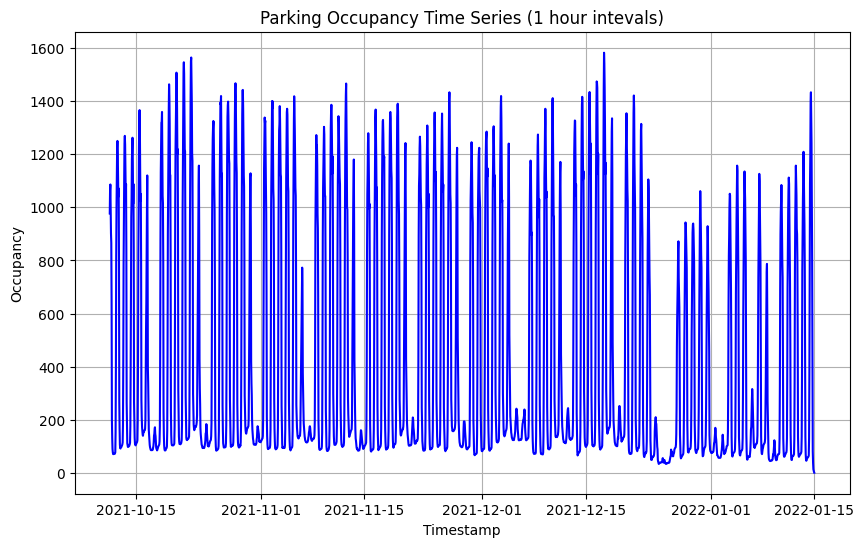

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller

# Read the CSV file into a pandas DataFrame with correct delimiter
df = pd.read_csv('../preprocess/parking_time_series_filtered_1_hour.csv', delimiter=',')

# Convert timestamp column to DateTime format
df['Time'] = pd.to_datetime(df['Time'])

# Set timestamp column as index (assuming it represents time)
df.set_index('Time', inplace=True)

# Seasonal differencing (assuming monthly seasonality)
df['Parkings_diff'] = df['Parkings'].diff(12)

# Drop NaNs introduced by differencing
df.dropna(subset=['Parkings_diff'], inplace=True)

# Plot the time series data
plt.figure(figsize=(10, 6))
plt.plot(df.index, df['Parkings'], color='blue')
plt.title('Parking Occupancy Time Series (1 hour intevals)')
plt.xlabel('Timestamp')
plt.ylabel('Occupancy')
plt.grid(True)
plt.show()


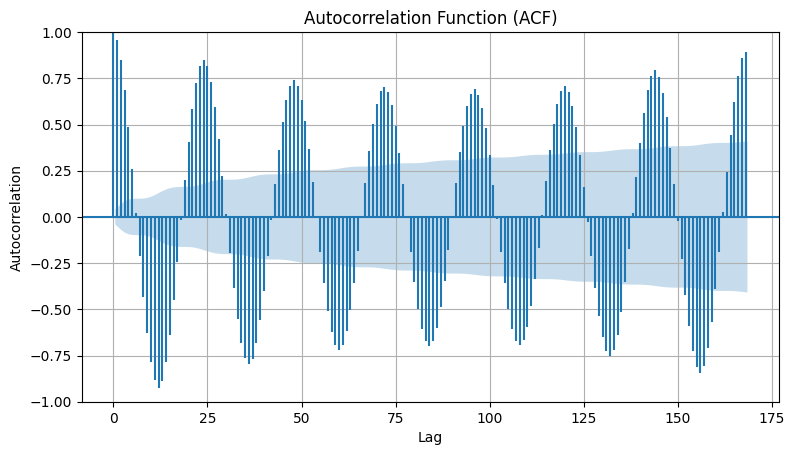

In [32]:

# Compute and plot autocorrelation function (ACF)
plot_acf(df['Parkings_diff'], lags=168 , alpha=0.05, marker='').set_figwidth(9)
plt.title('Autocorrelation Function (ACF)')
plt.xlabel('Lag')
plt.ylabel('Autocorrelation')
plt.grid(True)
plt.show()


ADF Statistic: -9.6863608055751
p-value: 1.1677117649123444e-16


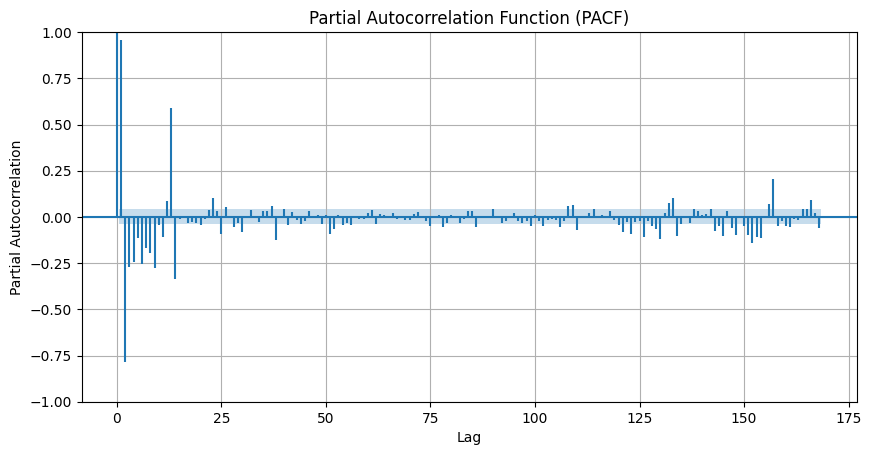

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.tsa.stattools import adfuller

# Read the CSV file into a pandas DataFrame with correct delimiter
df = pd.read_csv('../preprocess/parking_time_series_filtered_1_hour.csv', delimiter=',')

# Convert timestamp column to DateTime format
df['Time'] = pd.to_datetime(df['Time'])

# Set timestamp column as index (assuming it represents time)
df.set_index('Time', inplace=True)

# Ensure the data is sorted by timestamp (just in case)
df.sort_index(inplace=True)

# Seasonal differencing (assuming monthly seasonality)
df['Parkings_diff'] = df['Parkings'].diff(12)

# Drop NaNs introduced by differencing
df.dropna(subset=['Parkings_diff'], inplace=True)

# Check for stationarity using the Augmented Dickey-Fuller (ADF) test
result = adfuller(df['Parkings_diff'])
print('ADF Statistic:', result[0])
print('p-value:', result[1])

# Plot the partial autocorrelation function (PACF)
plot_pacf(df['Parkings_diff'], lags=168, marker='').set_figwidth(10)
plt.title('Partial Autocorrelation Function (PACF)')
plt.xlabel('Lag')
plt.ylabel('Partial Autocorrelation')
plt.grid(True)
plt.show()

ADF Statistic: -9.6863608055751
p-value: 1.1677117649123444e-16


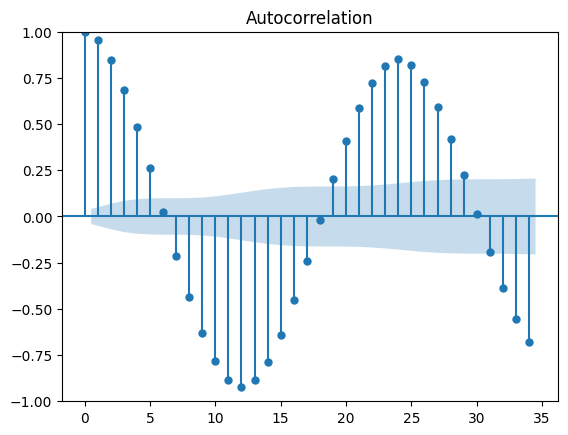

The time series is stationary.


In [27]:

# Perform Augmented Dickey-Fuller test to check stationarity
result = adfuller(df['Parkings_diff'])

# Print the test statistic and p-value
print('ADF Statistic:', result[0])
print('p-value:', result[1])

# Plot ACF to visualize autocorrelation
plot_acf(df['Parkings_diff'])
plt.show()

# Interpret the result
if result[1] <= 0.05:
    print("The time series is stationary.")
else:
    print("The time series is not stationary.")